# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# Global parameters
N = 15
alpha = 0.5
dt = 0.02
t_max = 8000.0
A_mala, A_velika = 0.12, 3.0
n_shrani = 50          # energije shranimo vsakih n_shrani korakov
t_max_term = 40000.0   # Naloga 3: termalizacija je pocasna

# Funkcije

In [2]:
# Simbolno: potencial vzmeti FPU-alpha in sila
r_s, a_s = sp.symbols("r alpha", real=True)
V_vez = r_s**2 / 2 + a_s * r_s**3 / 3
F_vez = sp.diff(V_vez, r_s)            # sila v vezi: r + alpha r^2

n = np.arange(1, N + 1)
k = np.arange(1, N + 1)
S = np.sqrt(2 / (N + 1)) * np.sin(np.outer(k, n) * np.pi / (N + 1))   # ortogonalna, S = S^T = S^-1
omega_k = 2 * np.sin(k * np.pi / (2 * (N + 1)))

In [3]:
def raztezki(u):
    return np.diff(np.concatenate(([0.0], u, [0.0])))

def pospesek(u, alpha=alpha):
    r = raztezki(u)
    F = r + alpha * r**2
    return F[1:] - F[:-1]

def energija(u, v, alpha=alpha):
    r = raztezki(u)
    return 0.5 * np.sum(v**2) + np.sum(r**2 / 2 + alpha * r**3 / 3)

def modalne(u, v):
    Q, P = S @ u, S @ v
    return 0.5 * (P**2 + (omega_k * Q)**2)

def verlet(u0, v0, dt=dt, t_max=t_max, alpha=alpha, n_shrani=n_shrani):
    u, v = u0.copy(), v0.copy()
    a = pospesek(u, alpha)
    n_kor = int(t_max / dt)
    t_s, E_s, Ek_s = [], [], []
    for i in range(n_kor + 1):
        if i % n_shrani == 0:
            t_s.append(i * dt)
            E_s.append(energija(u, v, alpha))
            Ek_s.append(modalne(u, v))
        v += 0.5 * dt * a
        u += dt * v
        a = pospesek(u, alpha)
        v += 0.5 * dt * a
    return np.array(t_s), np.array(E_s), np.array(Ek_s)

def zacetni(A):
    return A * np.sin(n * np.pi / (N + 1)), np.zeros(N)

def euler(u0, v0, dt, t_max, n_shrani=100):
    u, v, E = u0.copy(), v0.copy(), []
    for i in range(int(t_max / dt)):
        u, v = u + dt * v, v + dt * pospesek(u)
        if i % n_shrani == 0:
            E.append(energija(u, v))
        if not np.isfinite(u).all():
            break
    return np.array(E)

def rk4(u0, v0, dt, t_max, n_shrani=100):
    y, E = np.concatenate([u0, v0]), []
    f = lambda y: np.concatenate([y[N:], pospesek(y[:N])])
    for i in range(int(t_max / dt)):
        k1 = f(y); k2 = f(y + dt / 2 * k1); k3 = f(y + dt / 2 * k2); k4 = f(y + dt * k3)
        y = y + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        if i % n_shrani == 0:
            E.append(energija(y[:N], y[N:]))
    return np.array(E)

# Testno območje

Eq(F_{vez}, alpha*r**2 + r)

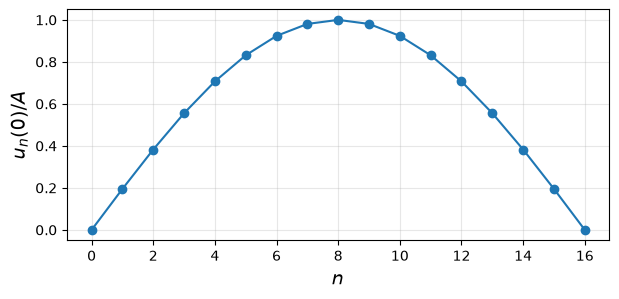

In [4]:
# Pripravljalna naloga 2: prvi lastni nacin, N = 15
display(sp.Eq(sp.Symbol("F_{vez}"), F_vez))
fig = plt.figure(figsize=(7, 3))
ax = fig.add_subplot(111)
ax.plot(np.arange(0, N + 2), np.concatenate(([0], np.sin(n * np.pi / (N + 1)), [0])), "o-")
ax.set_xlabel("$n$", fontsize=14)
ax.set_ylabel(r"$u_n(0) / A$", fontsize=14)
ax.grid(alpha=0.3)
plt.show()

C:\Users\Rene\AppData\Local\Temp\ipykernel_36472\1814698168.py:6: RuntimeWarning: overflow encountered in square
  F = r + alpha * r**2
C:\Users\Rene\AppData\Local\Temp\ipykernel_36472\1814698168.py:7: RuntimeWarning: invalid value encountered in subtract
  return F[1:] - F[:-1]


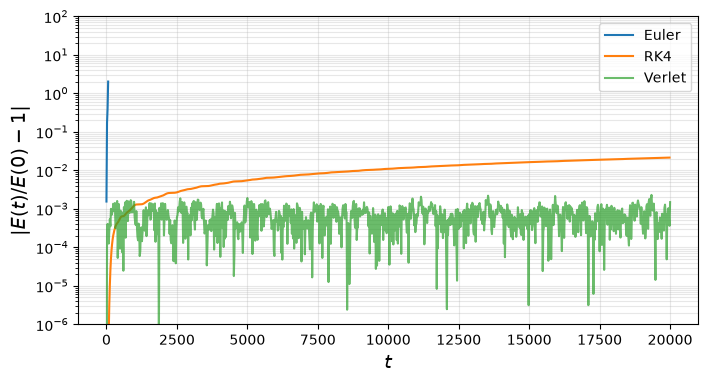

dt = 0.2, t = 20000: RK4 -2.1e-02 (drift), Verlet max 2.3e-03 (omejeno), Euler divergira pri t ~ 60


In [5]:
# Pripravljalna naloga 1: drift energije Euler / RK4 / Verlet (A = 1, vecji korak dt = 0.2)
u0, v0 = zacetni(1.0)
dt_cmp, t_cmp = 0.2, 20000.0
E0 = energija(u0, v0)
E_eu = euler(u0, v0, dt_cmp, t_cmp)
E_rk = rk4(u0, v0, dt_cmp, t_cmp)
t_v, E_v, _ = verlet(u0, v0, dt=dt_cmp, t_max=t_cmp, n_shrani=100)

t_ax = dt_cmp * 100 * np.arange(len(E_rk))
fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111)
ax.semilogy(t_ax[:len(E_eu)], np.abs(E_eu / E0 - 1) + 1e-17, label="Euler")
ax.semilogy(t_ax, np.abs(E_rk / E0 - 1) + 1e-17, label="RK4")
ax.semilogy(t_v, np.abs(E_v / E0 - 1) + 1e-17, label="Verlet", alpha=0.7)
ax.set_ylim(1e-6, 1e2)
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel(r"$|E(t)/E(0) - 1|$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.show()
print(f"dt = {dt_cmp}, t = {t_cmp:.0f}: RK4 {E_rk[-1] / E0 - 1:+.1e} (drift), "
      f"Verlet max {np.max(np.abs(E_v / E0 - 1)):.1e} (omejeno), Euler divergira pri t ~ {t_ax[len(E_eu) - 1]:.0f}")

# Naloga 1

A = 0.12: E_tot(0) = 2.213536e-03, max |dE/E| = 4.7e-06, |dE/E| na koncu = 3.1e-06


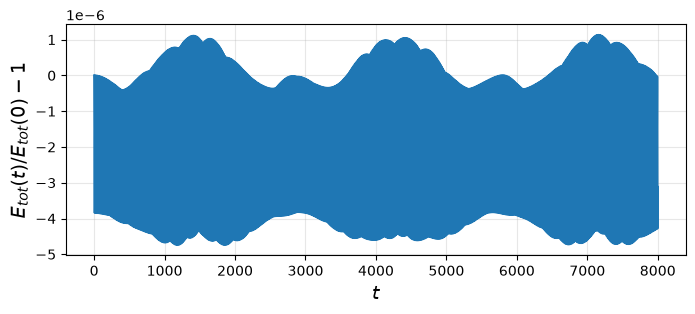

In [6]:
u0, v0 = zacetni(A_mala)
t_s, E_s, Ek_s = verlet(u0, v0)
dE = E_s / E_s[0] - 1
print(f"A = {A_mala}: E_tot(0) = {E_s[0]:.6e}, max |dE/E| = {np.max(np.abs(dE)):.1e}, |dE/E| na koncu = {abs(dE[-1]):.1e}")

fig = plt.figure(figsize=(8, 3))
ax = fig.add_subplot(111)
ax.plot(t_s, dE)
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel(r"$E_{tot}(t)/E_{tot}(0) - 1$", fontsize=14)
ax.grid(alpha=0.3)
plt.show()

# Naloga 2

A = 0.12: min E1/E = 0.736,  T_rec = 2883  (E1/E = 0.999)
A = 1.0: min E1/E = 0.009,  T_rec = 1167  (E1/E = 0.991)


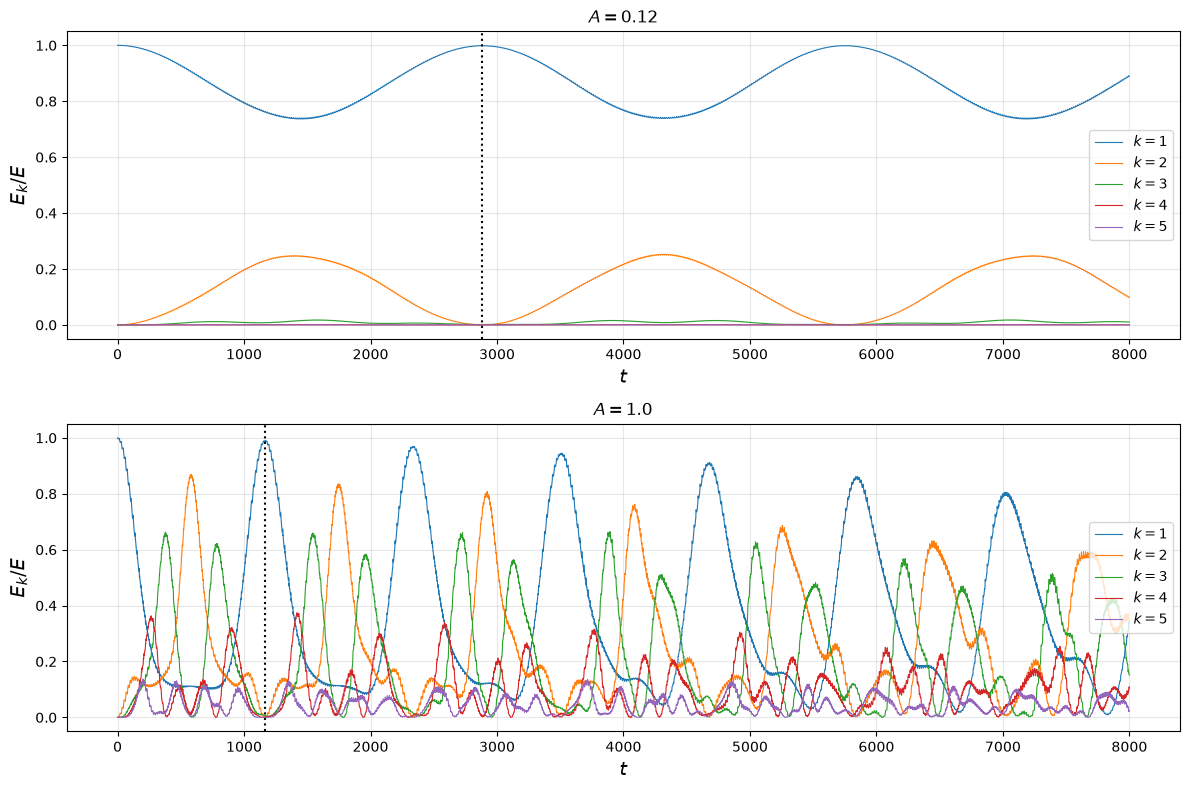

In [7]:
def rekurenca(t_s, delez1, prag=0.95):
    # E1 najprej pade pod polovico svojega razpona, T_rec = vrh prvega povratka nad prag
    meja = 0.5 * (1 + delez1.min())
    i_dol = np.argmax(delez1 < meja)
    gor = np.where((np.arange(len(delez1)) > i_dol) & (delez1 > prag))[0]
    if len(gor) == 0:
        return np.nan, np.nan
    i_gor = gor[0]
    i_kon = i_gor + np.argmax(delez1[i_gor:] < prag)
    i_vrh = i_gor + np.argmax(delez1[i_gor:i_kon])
    return t_s[i_vrh], delez1[i_vrh]

fig = plt.figure(figsize=(12, 8))
for i, A in enumerate([A_mala, 1.0]):
    t_s, E_s, Ek_s = verlet(*zacetni(A))
    delez = Ek_s / Ek_s.sum(axis=1, keepdims=True)
    T_rec, d_rec = rekurenca(t_s, delez[:, 0])
    print(f"A = {A}: min E1/E = {delez[:, 0].min():.3f},  T_rec = {T_rec:.0f}  (E1/E = {d_rec:.3f})")
    ax = fig.add_subplot(2, 1, i + 1)
    for kk in range(5):
        ax.plot(t_s, delez[:, kk], linewidth=0.8, label=f"$k = {kk + 1}$")
    ax.axvline(T_rec, color="black", linestyle=":")
    ax.set_title(f"$A = {A}$")
    ax.set_xlabel("$t$", fontsize=14)
    ax.set_ylabel(r"$E_k / E$", fontsize=14)
    ax.legend(loc="center right")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Naloga 3

A = 1.5: max |dE/E| = 3.3e-05,  normirana entropija = 0.662
A = 3.0: max |dE/E| = 1.5e-04,  normirana entropija = 0.994


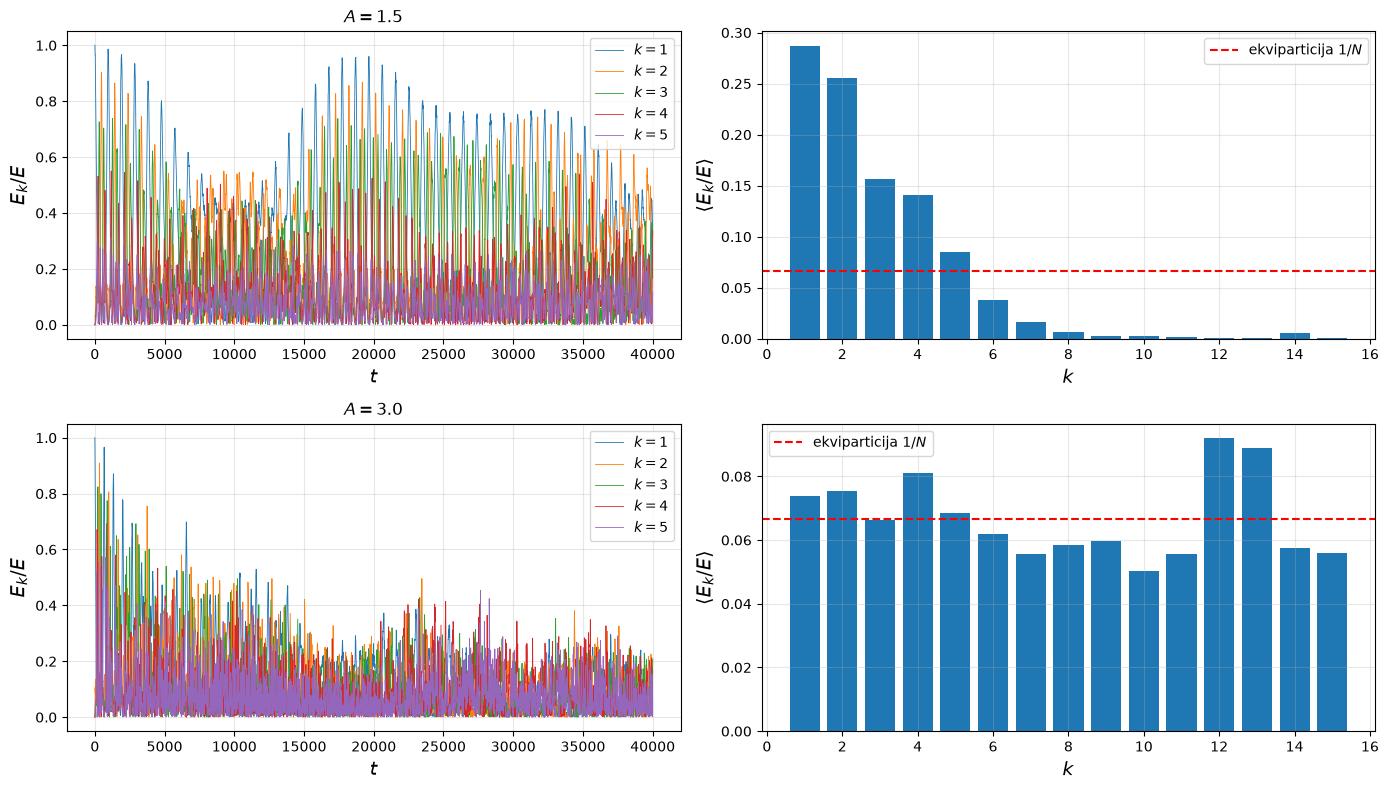

In [8]:
fig = plt.figure(figsize=(14, 8))
for i, A in enumerate([1.5, A_velika]):
    t_s, E_s, Ek_s = verlet(*zacetni(A), t_max=t_max_term, n_shrani=500)
    delez = Ek_s / Ek_s.sum(axis=1, keepdims=True)
    povp = delez[t_s > 0.75 * t_max_term].mean(axis=0)
    S_norm = -np.sum(povp * np.log(povp)) / np.log(N)      # 1 = popolna ekviparticija
    print(f"A = {A}: max |dE/E| = {np.max(np.abs(E_s / E_s[0] - 1)):.1e},  normirana entropija = {S_norm:.3f}")

    ax = fig.add_subplot(2, 2, 2 * i + 1)
    for kk in range(5):
        ax.plot(t_s, delez[:, kk], linewidth=0.6, label=f"$k = {kk + 1}$")
    ax.set_title(f"$A = {A}$")
    ax.set_xlabel("$t$", fontsize=14)
    ax.set_ylabel(r"$E_k / E$", fontsize=14)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

    ax = fig.add_subplot(2, 2, 2 * i + 2)
    ax.bar(k, povp)
    ax.axhline(1 / N, color="red", linestyle="--", label="ekviparticija $1/N$")
    ax.set_xlabel("$k$", fontsize=14)
    ax.set_ylabel(r"$\langle E_k / E \rangle$", fontsize=14)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()